#### Land-cover segmentation with U-Net and a Random Forest baseline


This notebook uses **LandCover.ai**, a labelled aerial-imagery dataset containing pixel-level annotations for background, buildings, woodland, water and roads. It trains a compact U-Net for semantic segmentation and compares it with a Random Forest baseline trained on RGB pixel values.

Dataset source: https://landcover.ai.linuxpolska.com/  
Dataset paper: Boguszewski et al. (2021), *LandCover.ai: Dataset for Automatic Mapping of Buildings, Woodlands, Water and Roads from Aerial Imagery*.  



## 1. Install dependencies

In [3]:
!pip -q install rasterio scikit-learn tqdm

#### 2. Library imports

In [4]:
import os, glob, random, time, zipfile, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import rasterio
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import jaccard_score, f1_score
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


#### 3. Download and extract LandCover.ai


In [5]:
DATA_DIR = Path("/content/landcover_ai")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / "landcover.ai.v1.zip"
URL = "https://landcover.ai.linuxpolska.com/download/landcover.ai.v1.zip"

if not ZIP_PATH.exists():
    print("Downloading official LandCover.ai v1 archive. This may take a while...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
else:
    print("Archive already exists:", ZIP_PATH)

extract_dir = DATA_DIR / "extracted"
if not extract_dir.exists() or not any(extract_dir.iterdir()):
    extract_dir.mkdir(parents=True, exist_ok=True)
    print("Extracting archive...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(extract_dir)
    print("Extraction complete.")
else:
    print("Using existing extracted files.")

print("Top-level entries:", [p.name for p in list(extract_dir.iterdir())[:15]])

Extracting archive...
Extraction complete.
Top-level entries: ['train.txt', 'split.py', 'val.txt', 'images', 'masks', 'test.txt']


#### 4. Checking image and mask files


In [6]:
tif_files = list(extract_dir.rglob("*.tif")) + list(extract_dir.rglob("*.tiff"))
print("GeoTIFF files found:", len(tif_files))
for p in tif_files[:30]:
    print(p.relative_to(extract_dir))

GeoTIFF files found: 82
images/N-34-140-A-d-3-4.tif
images/N-34-140-A-b-4-2.tif
images/M-33-20-D-c-4-2.tif
images/M-34-55-B-b-4-1.tif
images/M-33-7-A-d-2-3.tif
images/N-33-139-D-c-1-3.tif
images/M-34-65-D-d-4-1.tif
images/M-34-65-D-a-4-4.tif
images/N-34-61-B-a-1-1.tif
images/M-34-65-D-c-4-2.tif
images/N-34-140-A-d-4-2.tif
images/M-34-68-B-a-1-3.tif
images/N-33-119-C-c-3-3.tif
images/M-34-32-B-a-4-3.tif
images/N-34-77-A-b-1-4.tif
images/N-33-60-D-c-4-2.tif
images/N-34-140-A-b-3-2.tif
images/M-34-51-C-d-4-1.tif
images/M-34-5-D-d-4-2.tif
images/N-33-139-C-d-2-4.tif
images/N-33-104-A-c-1-1.tif
images/M-33-32-B-b-4-4.tif
images/N-33-130-A-d-3-3.tif
images/N-34-106-A-b-3-4.tif
images/N-34-97-D-c-2-4.tif
images/M-34-32-B-b-1-3.tif
images/N-34-106-A-c-1-3.tif
images/M-33-48-A-c-4-4.tif
images/N-34-97-C-b-1-2.tif
images/M-34-6-A-d-2-2.tif


#### 5. Pairing aerial images with masks



In [7]:
def pair_files(paths):
    paths = [Path(p) for p in paths]
    def is_mask_path(p):
        text = (p.stem + " " + " ".join(p.parts[:-1])).lower()
        return any(k in text for k in ["mask", "label", "groundtruth", "ground_truth", "annotation", "gt"])
    masks = [p for p in paths if is_mask_path(p)]
    images = [p for p in paths if p not in masks]
    pairs = []

    def normalise(stem):
        s = stem.lower()
        for token in ["_mask", "-mask", "mask_", "mask-", "_label", "-label",
                      "label_", "label-", "_gt", "-gt", "gt_", "gt-",
                      "_image", "-image", "image_", "image-", "_img", "-img",
                      "img_", "img-", "_rgb", "-rgb"]:
            s = s.replace(token, "")
        return s.strip("_- ")

    masks_by_norm = {}
    for m in masks:
        masks_by_norm.setdefault(normalise(m.stem), []).append(m)

    for img in images:
        key = normalise(img.stem)
        candidates = masks_by_norm.get(key, [])
        if candidates:
            pairs.append((img, candidates[0]))
    return pairs

pairs = pair_files(tif_files)
print("Candidate image/mask pairs:", len(pairs))
for a, b in pairs[:10]:
    print(a.name, "<->", b.name)

Candidate image/mask pairs: 41
N-34-140-A-d-3-4.tif <-> N-34-140-A-d-3-4.tif
N-34-140-A-b-4-2.tif <-> N-34-140-A-b-4-2.tif
M-33-20-D-c-4-2.tif <-> M-33-20-D-c-4-2.tif
M-34-55-B-b-4-1.tif <-> M-34-55-B-b-4-1.tif
M-33-7-A-d-2-3.tif <-> M-33-7-A-d-2-3.tif
N-33-139-D-c-1-3.tif <-> N-33-139-D-c-1-3.tif
M-34-65-D-d-4-1.tif <-> M-34-65-D-d-4-1.tif
M-34-65-D-a-4-4.tif <-> M-34-65-D-a-4-4.tif
N-34-61-B-a-1-1.tif <-> N-34-61-B-a-1-1.tif
M-34-65-D-c-4-2.tif <-> M-34-65-D-c-4-2.tif


#### 6. Raster dimensions and label values inspection

Image shape (bands, H, W): (3, 9579, 8885) dtype: uint8
Mask shape: (9579, 8885) dtype: uint8
Unique mask values (sample): [0 1 2 3 4]


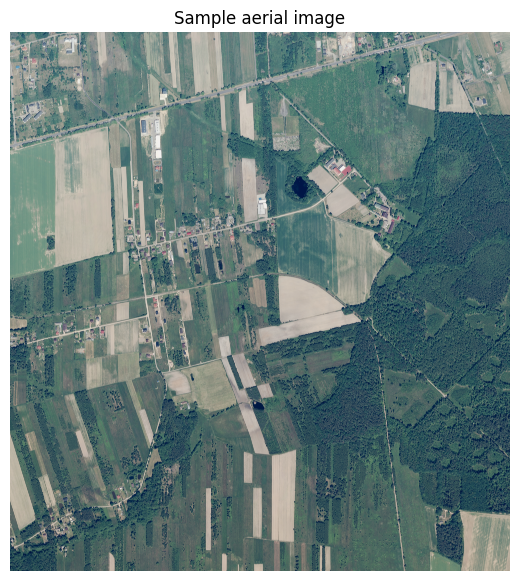

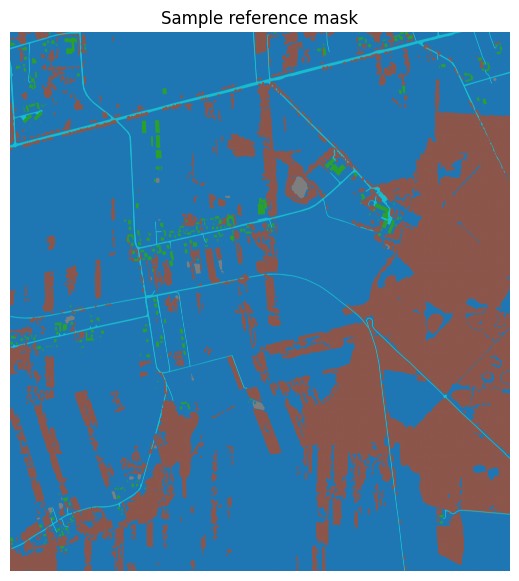

In [8]:
if not pairs:
    raise RuntimeError("No image-mask pairs found. Inspect the GeoTIFF filenames above and update pair_files() before proceeding.")

img_path, mask_path = pairs[0]
with rasterio.open(img_path) as src:
    sample_img = src.read()
    print("Image shape (bands, H, W):", sample_img.shape, "dtype:", sample_img.dtype)
with rasterio.open(mask_path) as src:
    sample_mask = src.read(1)
    print("Mask shape:", sample_mask.shape, "dtype:", sample_mask.dtype)
    print("Unique mask values (sample):", np.unique(sample_mask)[:30])

if sample_img.shape[0] >= 3:
    rgb = np.moveaxis(sample_img[:3], 0, -1)
    if np.issubdtype(rgb.dtype, np.integer):
        rgb = rgb.astype(np.float32) / max(np.iinfo(sample_img.dtype).max, 1)
    else:
        rgb = rgb.astype(np.float32)
        if rgb.max() > 1:
            rgb = rgb / 255.0
    plt.figure(figsize=(7, 7))
    plt.imshow(np.clip(rgb, 0, 1))
    plt.title("Sample aerial image")
    plt.axis("off")
    plt.show()

plt.figure(figsize=(7, 7))
plt.imshow(sample_mask, cmap="tab10")
plt.title("Sample reference mask")
plt.axis("off")
plt.show()

#### 7. Make fixed-size patches

I used 256 × 256 patches. The notebook samples patches from paired images and then splits the patches into train, validation and test sets.

In [9]:
PATCH = 256
MAX_PATCHES_PER_IMAGE = 30
MAX_TOTAL_PATCHES = 700  # reduce to 300 if memory or runtime is limited

def normalise_rgb(arr):
    # arr shape: bands,H,W; return float32 RGB in [0,1]
    arr = np.moveaxis(arr[:3], 0, -1)
    arr = arr.astype(np.float32)
    if arr.max() > 1:
        arr /= 255.0
    return np.clip(arr, 0, 1)

def map_mask_values(mask):
    # Expected official v1 values: background=0, building=1, woodland=2, water=3, road=4.
    # If your inspected unique values differ, stop and adapt this mapping.
    return mask.astype(np.int64)

patch_records = []
rng = np.random.default_rng(SEED)

for img_path, mask_path in tqdm(pairs, desc="Creating patches"):
    with rasterio.open(img_path) as src:
        image = src.read()
    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    if image.shape[0] < 3:
        continue
    h = min(image.shape[1], mask.shape[0])
    w = min(image.shape[2], mask.shape[1])
    image = image[:3, :h, :w]
    mask = mask[:h, :w]

    possible = [(y, x) for y in range(0, h - PATCH + 1, PATCH)
                       for x in range(0, w - PATCH + 1, PATCH)]
    if not possible:
        continue
    if len(possible) > MAX_PATCHES_PER_IMAGE:
        chosen = rng.choice(len(possible), size=MAX_PATCHES_PER_IMAGE, replace=False)
        possible = [possible[i] for i in chosen]

    for y, x in possible:
        im = normalise_rgb(image[:, y:y+PATCH, x:x+PATCH])
        ma = map_mask_values(mask[y:y+PATCH, x:x+PATCH])
        if im.shape[:2] == (PATCH, PATCH) and ma.shape == (PATCH, PATCH):
            patch_records.append((im, ma, img_path.name))
        if len(patch_records) >= MAX_TOTAL_PATCHES:
            break
    if len(patch_records) >= MAX_TOTAL_PATCHES:
        break

print("Patches created:", len(patch_records))
if len(patch_records) < 60:
    raise RuntimeError("Too few patches were created. Inspect image/mask pairing, dimensions and archive layout.")

Creating patches:   0%|          | 0/41 [00:00<?, ?it/s]

Patches created: 700


#### 8. Class labels and patches visualization

Label values found: [0 1 2 3 4]


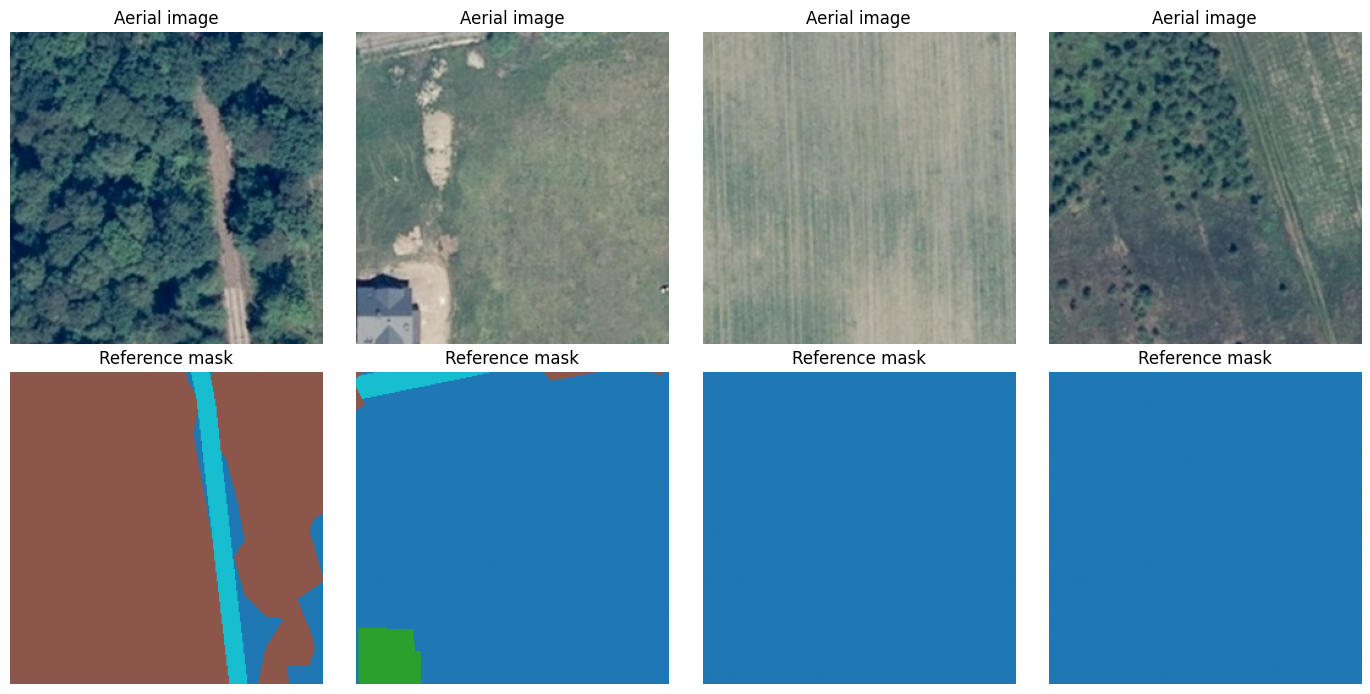

In [10]:
CLASS_NAMES = ["Background", "Building", "Woodland", "Water", "Road"]
NUM_CLASSES = 5

all_labels = np.unique(np.concatenate([m.reshape(-1) for _, m, _ in patch_records]))
print("Label values found:", all_labels)
if not set(all_labels.tolist()).issubset(set(range(NUM_CLASSES))):
    raise ValueError("Unexpected mask label values. Inspect masks and update map_mask_values() before training.")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    im, ma, _ = patch_records[i]
    axes[0, i].imshow(im)
    axes[0, i].set_title("Aerial image")
    axes[1, i].imshow(ma, vmin=0, vmax=4, cmap="tab10")
    axes[1, i].set_title("Reference mask")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

#### 9. Split data and create PyTorch loaders

This is a prototype split. Since neighbouring patches from the same orthophoto can be highly similar.

In [11]:
indices = np.arange(len(patch_records))
rng.shuffle(indices)
n_train = int(0.70 * len(indices))
n_val = int(0.15 * len(indices))
train_ids = indices[:n_train]
val_ids = indices[n_train:n_train+n_val]
test_ids = indices[n_train+n_val:]

class PatchDataset(Dataset):
    def __init__(self, records, ids):
        self.records = records
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, idx):
        image, mask, _ = self.records[self.ids[idx]]
        # RGB to CHW; scale 0..1 to normalised 0..1 inputs
        x = torch.from_numpy(image.transpose(2, 0, 1).copy()).float()
        y = torch.from_numpy(mask.copy()).long()
        return x, y

BATCH_SIZE = 8
train_ds = PatchDataset(patch_records, train_ids)
val_ds = PatchDataset(patch_records, val_ids)
test_ds = PatchDataset(patch_records, test_ids)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
                         pin_memory=torch.cuda.is_available())

print("Train:", len(train_ds), "Validation:", len(val_ds), "Test:", len(test_ds))

Train: 489 Validation: 105 Test: 106


#### 10. Random Forest pixel-classification baseline

The baseline predicts a class for each pixel from its RGB values. This is a simple baseline, not a fully tuned RF model.

In [20]:
# Sample training pixels separately from each class
MAX_PIXELS_PER_CLASS = 30_000

X_parts, y_parts = [], []
rng = np.random.default_rng(SEED)

for class_id, class_name in enumerate(class_names):
    class_pixels = []

    # Gather pixels of this class from TRAINING patches only
    for idx in train_ids:
        image, mask, _ = patch_records[idx]

        pixels = image.reshape(-1, 3)
        labels = mask.reshape(-1)

        matching = np.flatnonzero(labels == class_id)

        if len(matching) > 0:
            class_pixels.append(pixels[matching])

    if not class_pixels:
        print(f"WARNING: No training pixels for {class_name}")
        continue

    class_pixels = np.concatenate(class_pixels)
    n_take = min(MAX_PIXELS_PER_CLASS, len(class_pixels))

    selected = rng.choice(
        len(class_pixels),
        size=n_take,
        replace=False
    )

    X_parts.append(class_pixels[selected])
    y_parts.append(
        np.full(n_take, class_id, dtype=np.uint8)
    )

X_rf = np.concatenate(X_parts).astype(np.float32)
y_rf = np.concatenate(y_parts).astype(np.uint8)

print("Balanced RF sample counts:")
print(np.bincount(y_rf, minlength=NUM_CLASSES))

rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=25,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED,
    class_weight="balanced"
)

start = time.time()
rf.fit(X_rf, y_rf)

print(f"Random Forest trained in {time.time()-start:.1f} seconds.")
print("Classes learned by RF:", rf.classes_)

Balanced RF sample counts:
[30000 30000 30000 30000 30000]
Random Forest trained in 19.2 seconds.
Classes learned by RF: [0 1 2 3 4]


#### 11. Defining a compact U-Net

In [13]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, n_classes=5, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = DoubleConv(in_ch, base)
        self.e2 = DoubleConv(base, base*2)
        self.e3 = DoubleConv(base*2, base*4)
        self.e4 = DoubleConv(base*4, base*8)
        self.b = DoubleConv(base*8, base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, 2)
        self.d4 = DoubleConv(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8, base*4, 2, 2)
        self.d3 = DoubleConv(base*8, base*4)
        self.u2 = nn.ConvTranspose2d(base*4, base*2, 2, 2)
        self.d2 = DoubleConv(base*4, base*2)
        self.u1 = nn.ConvTranspose2d(base*2, base, 2, 2)
        self.d1 = DoubleConv(base*2, base)
        self.head = nn.Conv2d(base, n_classes, 1)
    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        e4 = self.e4(self.pool(e3))
        b = self.b(self.pool(e4))
        d4 = self.d4(torch.cat([self.u4(b), e4], 1))
        d3 = self.d3(torch.cat([self.u3(d4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)

model = UNet().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Parameters: 1,942,645


## 12. Metrics and training

In [19]:
# Calculating class weights from training masks
NUM_CLASSES = 5

class_names = [
    "Background", "Building", "Woodland", "Water", "Road"
]

pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for idx in train_ids:
    _, mask, _ = patch_records[idx]
    pixel_counts += np.bincount(
        mask.ravel(), minlength=NUM_CLASSES
    )[:NUM_CLASSES]

print("Training pixel counts:")
for name, count in zip(class_names, pixel_counts):
    print(f"{name}: {count:,}")

frequencies = pixel_counts / pixel_counts.sum()
weights = 1.0 / np.sqrt(np.maximum(frequencies, 1e-8))
weights = weights / weights.mean()

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=DEVICE
)

print("\nClass weights:")
for name, weight in zip(class_names, class_weights.cpu().numpy()):
    print(f"{name}: {weight:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights)


#Defining evaluation metrics
@torch.no_grad()
def evaluate_unet(model, loader):
    model.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    losses = []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        losses.append(criterion(logits, y).item())
        pred = logits.argmax(1)

        yt = y.cpu().numpy().ravel()
        yp = pred.cpu().numpy().ravel()

        cm += confusion_matrix(
            yt, yp, labels=list(range(NUM_CLASSES))
        )

    tp = np.diag(cm).astype(float)
    denom = cm.sum(0) + cm.sum(1) - tp
    iou = tp / np.maximum(denom, 1)
    dice = 2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1)

    return {
        "loss": float(np.mean(losses)),
        "miou": float(iou.mean()),
        "mean_dice": float(dice.mean()),
        "per_class_iou": iou,
        "confusion": cm
    }


# U-Net model
model = UNet().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

EPOCHS = 15
PATIENCE = 4
best_miou = -1.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_miou": [],
    "val_dice": []
}

best_path = "/content/best_unet_weighted.pth"


#Train model, save the best model
for epoch in range(EPOCHS):
    model.train()
    losses = []
    start = time.time()

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    val = evaluate_unet(model, val_loader)
    train_loss = float(np.mean(losses))

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val["loss"])
    history["val_miou"].append(val["miou"])
    history["val_dice"].append(val["mean_dice"])

    if val["miou"] > best_miou:
        best_miou = val["miou"]
        epochs_without_improvement = 0
        torch.save(model.state_dict(), best_path)
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"val loss={val['loss']:.4f} | "
        f"val mIoU={val['miou']:.4f} | "
        f"val Dice={val['mean_dice']:.4f} | "
        f"{time.time()-start:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

#best validation checkpoint
model.load_state_dict(
    torch.load(best_path, map_location=DEVICE)
)

print("Best validation mIoU:", round(best_miou, 4))


Training pixel counts:
Background: 17,234,936
Building: 168,139
Woodland: 12,441,462
Water: 1,742,920
Road: 459,647

Class weights:
Background: 0.232
Building: 2.347
Woodland: 0.273
Water: 0.729
Road: 1.419
Epoch 1/15 | train loss=1.2799 | val loss=0.9896 | val mIoU=0.2867 | val Dice=0.3609 | 7.7s
Epoch 2/15 | train loss=1.1018 | val loss=0.9120 | val mIoU=0.2770 | val Dice=0.3479 | 7.7s
Epoch 3/15 | train loss=1.0260 | val loss=1.1020 | val mIoU=0.1585 | val Dice=0.2382 | 7.8s
Epoch 4/15 | train loss=0.9801 | val loss=1.1103 | val mIoU=0.2396 | val Dice=0.3211 | 8.0s
Epoch 5/15 | train loss=0.9641 | val loss=0.8967 | val mIoU=0.2523 | val Dice=0.3365 | 7.9s
Early stopping triggered.
Best validation mIoU: 0.2867


#### 13. U-Net and Random Forest on the same held-out patches evaluation

Both models are evaluated against the same reference masks. Metrics are pixel-level mean IoU and mean Dice over the five classes. Because this is a small, randomly split prototype, results are exploratory and should not be treated as a rigorous benchmark.

In [21]:
@torch.no_grad()
def predict_unet_patch(image):
    x = torch.from_numpy(image.transpose(2,0,1).copy()).float().unsqueeze(0).to(DEVICE)
    return model(x).argmax(1).squeeze(0).cpu().numpy()

def evaluate_rf(records, ids):
    ys, ps = [], []
    for idx in ids:
        image, mask, _ = records[idx]
        pred = rf.predict(image.reshape(-1, 3)).reshape(mask.shape)
        ys.append(mask.ravel())
        ps.append(pred.ravel())
    y = np.concatenate(ys)
    p = np.concatenate(ps)
    return {
        "miou": float(jaccard_score(y, p, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "mean_dice": float(f1_score(y, p, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)),
        "y": y, "pred": p
    }

unet_y, unet_p = [], []
for idx in test_ids:
    image, mask, _ = patch_records[idx]
    pred = predict_unet_patch(image)
    unet_y.append(mask.ravel())
    unet_p.append(pred.ravel())
unet_y = np.concatenate(unet_y)
unet_p = np.concatenate(unet_p)
unet_miou = jaccard_score(unet_y, unet_p, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
unet_dice = f1_score(unet_y, unet_p, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)

rf_result = evaluate_rf(patch_records, test_ids)
print("HELD-OUT PATCH RESULTS")
print(f"U-Net:          mIoU={unet_miou:.4f} | mean Dice={unet_dice:.4f}")
print(f"Random Forest:  mIoU={rf_result['miou']:.4f} | mean Dice={rf_result['mean_dice']:.4f}")
print("\nU-Net classification report:")
print(classification_report(unet_y, unet_p, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, zero_division=0))
print("\nRandom Forest classification report:")
print(classification_report(rf_result["y"], rf_result["pred"], labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, zero_division=0))

HELD-OUT PATCH RESULTS
U-Net:          mIoU=0.2774 | mean Dice=0.3516
Random Forest:  mIoU=0.2263 | mean Dice=0.3355

U-Net classification report:
              precision    recall  f1-score   support

  Background       0.77      0.82      0.80   3699218
    Building       0.01      0.00      0.00     25259
    Woodland       0.77      0.77      0.77   2733621
       Water       0.15      0.05      0.08    397767
        Road       0.09      0.16      0.11     90951

    accuracy                           0.74   6946816
   macro avg       0.36      0.36      0.35   6946816
weighted avg       0.72      0.74      0.73   6946816


Random Forest classification report:
              precision    recall  f1-score   support

  Background       0.75      0.49      0.59   3699218
    Building       0.03      0.57      0.06     25259
    Woodland       0.64      0.56      0.60   2733621
       Water       0.26      0.54      0.35    397767
        Road       0.04      0.39      0.08     90951



#### 14. Visual comparison of image, reference mask, U-Net and Random Forest

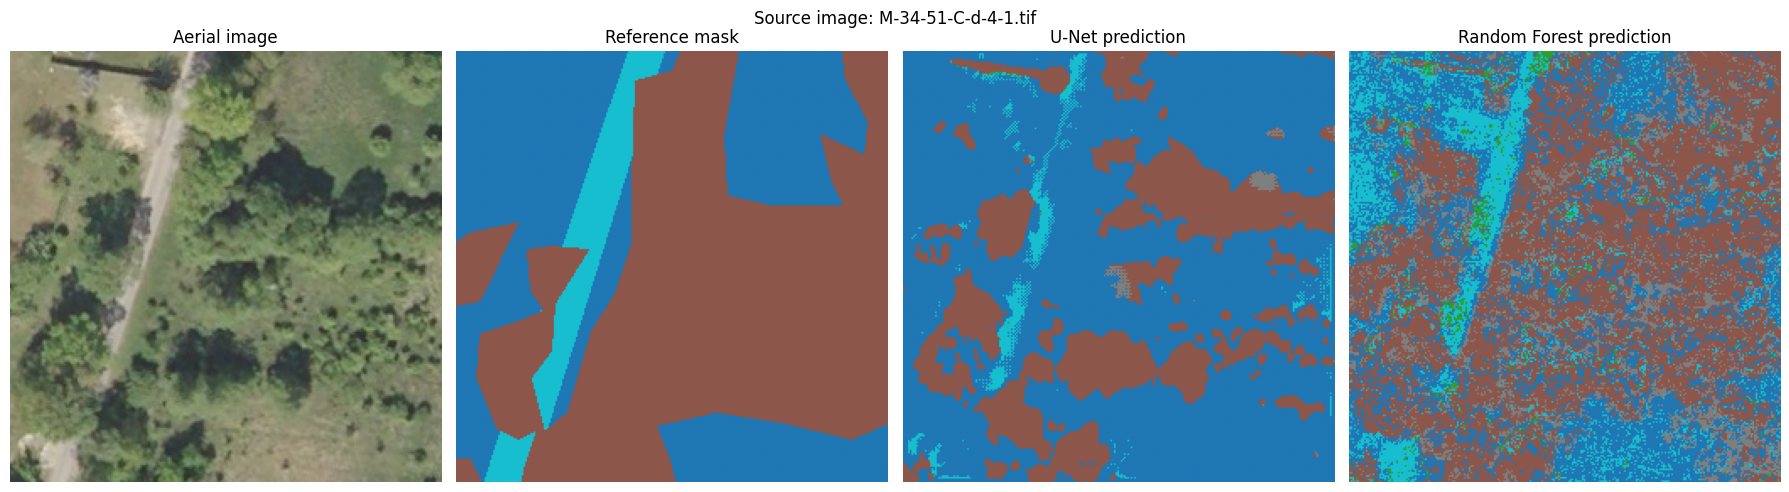

In [22]:
test_idx = int(test_ids[0])
image, mask, source_name = patch_records[test_idx]
unet_pred = predict_unet_patch(image)
rf_pred = rf.predict(image.reshape(-1, 3)).reshape(mask.shape)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(image); axes[0].set_title("Aerial image")
axes[1].imshow(mask, vmin=0, vmax=4, cmap="tab10"); axes[1].set_title("Reference mask")
axes[2].imshow(unet_pred, vmin=0, vmax=4, cmap="tab10"); axes[2].set_title("U-Net prediction")
axes[3].imshow(rf_pred, vmin=0, vmax=4, cmap="tab10"); axes[3].set_title("Random Forest prediction")
for ax in axes: ax.axis("off")
plt.suptitle(f"Source image: {source_name}")
plt.tight_layout()
plt.show()

#### 15. Training curves

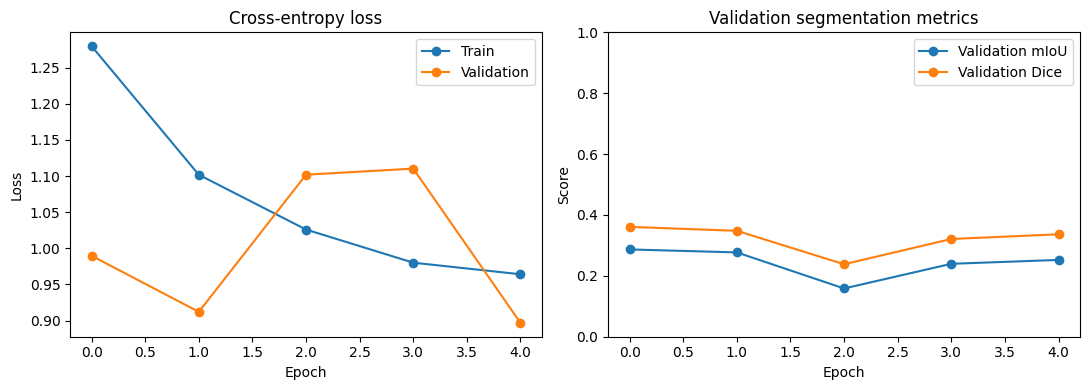

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Plot training and validation loss
axes[0].plot(history["train_loss"], marker="o", label="Train")
axes[0].plot(history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Plot validation metrics
axes[1].plot(
    history["val_miou"], marker="o", label="Validation mIoU"
)
axes[1].plot(
    history["val_dice"], marker="o", label="Validation Dice"
)
axes[1].set_title("Validation segmentation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

#### 16. Saving metrics and model checkpoints

In [24]:
import json
results = {
    "dataset": "LandCover.ai v1 aerial imagery",
    "classes": CLASS_NAMES,
    "model": "U-Net implemented in PyTorch",
    "baseline": "RandomForestClassifier using RGB pixel values",
    "patch_size": PATCH,
    "patch_count": len(patch_records),
    "train_patches": len(train_ids),
    "validation_patches": len(val_ids),
    "test_patches": len(test_ids),
    "epochs": EPOCHS,
    "unet_test_mIoU": float(unet_miou),
    "unet_test_mean_dice": float(unet_dice),
    "random_forest_test_mIoU": float(rf_result["miou"]),
    "random_forest_test_mean_dice": float(rf_result["mean_dice"]),
    "seed": SEED,
    "note": "Exploratory random patch split; possible spatial leakage. Not a rigorous benchmark."
}
with open("/content/landcover_results.json", "w") as f:
    json.dump(results, f, indent=2)
torch.save(model.state_dict(), "/content/unet_landcoverai_final.pth")
joblib.dump(rf, "/content/random_forest_rgb_baseline.joblib")
print(json.dumps(results, indent=2))

{
  "dataset": "LandCover.ai v1 aerial imagery",
  "classes": [
    "Background",
    "Building",
    "Woodland",
    "Water",
    "Road"
  ],
  "model": "U-Net implemented in PyTorch",
  "baseline": "RandomForestClassifier using RGB pixel values",
  "patch_size": 256,
  "patch_count": 700,
  "train_patches": 489,
  "validation_patches": 105,
  "test_patches": 106,
  "epochs": 15,
  "unet_test_mIoU": 0.2773767617158197,
  "unet_test_mean_dice": 0.35158633179036747,
  "random_forest_test_mIoU": 0.22628183640228472,
  "random_forest_test_mean_dice": 0.3354803617435604,
  "seed": 42,
  "note": "Exploratory random patch split; possible spatial leakage. Not a rigorous benchmark."
}
